# 03 - Exploratory Data Analysis: OSV Advisory Data

**Questions addressed:**
1. Is the advisory table clean and consistent with what notebook 01 found? (reconciliation)
2. How are advisories distributed across packages, severities, id prefixes, and time?
3. What does the 2026 surge look like: broad or concentrated, bursty or steady, new vs repeat packages, and does it persist without the 20 most affected packages?
4. What do the planned label windows (docs/04 section 3) look like: positives per snapshot date, first-time vs repeat positives, and overlap between consecutive dates?
5. Are the OSV affected-version ranges clean enough for the planned matcher (docs/05 section 4)? What odd cases exist?
6. Which sample lockfile makes the best demo candidate (at the package name level)?

**Rules:** Report numbers and distributions only. The cause of the 2026 rise in advisories is NOT established and no causal explanation is asserted.

In [36]:
# Setup: Find project root and define standard directories
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / 'ml').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / 'data'
FIG = ROOT / 'docs' / 'figures' / 'eda_advisories'
FIG.mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT)

Project root: D:\DepRadar


In [37]:
# Config: Constants and comparison window annotations
HORIZON_MONTHS = 6
STRICT_RECONCILE = True        # set False ONLY for smoke tests on synthetic data
PRE_PERIOD = ('2023-01-01', '2025-08-31')   # comparison windows for Part D.
SURGE_PERIOD = ('2025-09-01', None)         # They are annotations chosen from the monthly chart, not findings.
SEED = 0

In [38]:
# HELPERS - monthly_grid / assign_splits / apply_embargo / label_counts will move to ml/eval/splits.py and ml/features/build_labels.py later
import pandas as pd

SPLIT_MONTHS = {            # target months, from docs/04_ML_SPEC.md section 3
    "train":   ("2023-01", "2024-01"),
    "val":     ("2024-07", "2024-09"),
    "test_a":  ("2025-03", "2025-05"),
    "test_b":  ("2025-11", "2026-04"),
}

def monthly_grid(snap_times, first="2023-01", last="2026-04", horizon=HORIZON_MONTHS):
    """One real snapshot per target month: the snapshot closest to the 1st of that month.
    Drops dates whose label window (T + horizon months) ends after the latest snapshot."""
    snaps = pd.Series(pd.to_datetime(snap_times, utc=True)).sort_values().reset_index(drop=True)
    latest = snaps.max()
    rows = []
    for month in pd.period_range(first, last, freq="M"):
        target = pd.Timestamp(month.start_time, tz="UTC")
        T = snaps.iloc[(snaps - target).abs().argmin()]
        rows.append({"target_month": str(month), "T": T})
    g = pd.DataFrame(rows).drop_duplicates("T").reset_index(drop=True)
    g["window_end"] = g["T"] + pd.DateOffset(months=horizon)
    return g[g["window_end"] <= latest].reset_index(drop=True)

def assign_splits(grid, split_months=SPLIT_MONTHS):
    g = grid.copy(); g["split"] = None
    for name, (a, b) in split_months.items():
        g.loc[(g.target_month >= a) & (g.target_month <= b), "split"] = name
    return g[g.split.notna()].reset_index(drop=True)

def apply_embargo(g, order=("train", "val", "test_a", "test_b"), horizon=HORIZON_MONTHS):
    """Drop leading dates of each split until next.T_min.date() > (prev.T_max + horizon months).date().
    Returns (filtered grid, list of dropped T)."""
    g = g.copy(); dropped = []
    for prev, nxt in zip(order, order[1:]):
        if not (g.split == prev).any() or not (g.split == nxt).any():
            continue
        limit = (g.loc[g.split == prev, "T"].max() + pd.DateOffset(months=horizon)).date()
        while (g.split == nxt).any() and g.loc[g.split == nxt, "T"].min().date() <= limit:
            idx = g.loc[g.split == nxt, "T"].idxmin()
            dropped.append(g.loc[idx, "T"]); g = g.drop(idx)
    return g.reset_index(drop=True), dropped

def label_counts(adv, T, horizon=HORIZON_MONTHS):
    """Vulnerability labels at T: positive = package with a NEW non-withdrawn vulnerability advisory published in (T, T+horizon]."""
    end = T + pd.DateOffset(months=horizon)
    d = adv[(adv.kind == "vulnerability") & adv.withdrawn.isna() & adv.published.notna()]
    win = d[(d.published > T) & (d.published <= end)]
    pos, prior = set(win.package), set(d[d.published <= T].package)
    return {"T": T, "window_end": end, "advisories_in_window": win.osv_id.nunique(), "positive_packages": len(pos),
            "first_time_positives": len(pos - prior), "repeat_positives": len(pos & prior),
            "packages_with_prior_advisory": len(prior)}

RESULTS = []   # (check name, actual, expected, ok)
def check(name, actual, expected, tol=0):
    ok = abs(actual - expected) <= tol
    RESULTS.append((name, actual, expected, ok))
    print(('PASS' if ok else 'FAIL'), name, '| actual =', actual, '| expected =', expected)
    if STRICT_RECONCILE and not ok:
        raise AssertionError(f'Reconciliation failed: {name}. Do NOT change the expected value; report the mismatch.')

## Part A - Load, integrity, reconciliation
**Question:** Is the advisory table clean, properly typed, and consistent with what notebook 01 found?
**How to read:** Tables report shape, types, missing values, timestamps, and integrity metrics. The reconciliation block executes automated checks comparing values against notebook 01.

In [39]:
# Load advisories and snapshots parquet tables and confirm UTC timestamps
import numpy as np

adv = pd.read_parquet(DATA / 'interim' / 'advisories_osv.parquet')
snaps = pd.read_parquet(DATA / 'raw' / 'deps_dev' / 'snapshots.parquet')

print(f"adv shape: {adv.shape}, memory: {adv.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print("adv dtypes:\n", adv.dtypes)
for col in ['published', 'modified', 'withdrawn']:
    assert adv[col].dt.tz is not None and str(adv[col].dt.tz) == 'UTC', f"{col} not UTC"
print("Confirmed: published, modified, withdrawn are tz-aware UTC.")

adv shape: (233041, 10), memory: 42.7 MB
adv dtypes:
 osv_id                           str
package                          str
published        datetime64[us, UTC]
modified         datetime64[ns, UTC]
withdrawn        datetime64[us, UTC]
severity                         str
aliases                          str
ranges_json                      str
versions_json                    str
kind                             str
dtype: object
Confirmed: published, modified, withdrawn are tz-aware UTC.


In [40]:
# Null counts per column split by kind and severity missingness share
nulls_by_kind = adv.groupby('kind').apply(lambda g: g.isna().sum(), include_groups=False).T
print("Null counts per column by kind:\n", nulls_by_kind)

sev_null_share = adv.groupby('kind')['severity'].apply(lambda s: s.isna().mean())
print("\nSeverity null share by kind:\n", sev_null_share)

Null counts per column by kind:
 kind           malware  vulnerability
osv_id               0              0
package              0              0
published            0              0
modified             0              0
withdrawn       222094          10169
severity        222425              4
aliases              0              0
ranges_json          0              0
versions_json        0              0

Severity null share by kind:
 kind
malware          1.000000
vulnerability    0.000377
Name: severity, dtype: float64


In [41]:
# Integrity counters: duplicate keys, ordering violations, bounds, and max packages
dup_keys = int(adv.duplicated(subset=['osv_id', 'package']).sum())
pub_gt_mod = int((adv['published'] > adv['modified']).sum())
withdrawn_lt_pub = int((adv['withdrawn'].notna() & (adv['withdrawn'] < adv['published'])).sum())
pub_gt_max_mod = int((adv['published'] > adv['modified'].max()).sum())
max_pkg_per_adv = int(adv.groupby('osv_id')['package'].nunique().max())

df_integrity = pd.DataFrame([{
    'duplicate_osv_pkg': dup_keys,
    'published_gt_modified': pub_gt_mod,
    'withdrawn_lt_published': withdrawn_lt_pub,
    'published_gt_max_modified': pub_gt_max_mod,
    'max_packages_in_advisory': max_pkg_per_adv
}])
print("Integrity counters (1 row):\n", df_integrity)

time_bounds = adv.groupby('kind').agg(
    pub_min=('published', 'min'), pub_max=('published', 'max'), mod_max=('modified', 'max')
)
print("\nTime bounds per kind:\n", time_bounds)
print("Data end (overall modified.max()):", adv['modified'].max())

Integrity counters (1 row):
    duplicate_osv_pkg  published_gt_modified  withdrawn_lt_published  \
0               2126                    203                       3   

   published_gt_max_modified  max_packages_in_advisory  
0                          0                        42  

Time bounds per kind:
                                 pub_min                   pub_max  \
kind                                                                
malware       2021-11-15 00:00:00+00:00 2026-10-11 07:35:19+00:00   
vulnerability 2017-10-24 18:33:35+00:00 2026-10-09 20:56:52+00:00   

                                          mod_max  
kind                                               
malware       2026-10-11 08:00:04.939413280+00:00  
vulnerability 2026-10-09 21:15:05.360447760+00:00  
Data end (overall modified.max()): 2026-10-11 08:00:04.939413280+00:00


In [42]:
# Reconciliation checks: table dimensions, kinds, prefixes, publication years and months
check('rows', len(adv), 233041)
check('distinct osv_id', adv.osv_id.nunique(), 230262)
check('distinct package', adv.package.nunique(), 225731)

kc = adv.kind.value_counts()
check('malware rows', kc.get('malware', 0), 222425)
check('vulnerability rows', kc.get('vulnerability', 0), 10616)

prefix = adv.osv_id.str.split('-').str[0].value_counts()
check('prefix MAL', prefix.get('MAL', 0), 222425)
check('prefix GHSA', prefix.get('GHSA', 0), 10614)
check('prefix EEF', prefix.get('EEF', 0), 1)
check('prefix GSD', prefix.get('GSD', 0), 1)

check('withdrawn rows', adv.withdrawn.notna().sum(), 778)
check('missing published', adv.published.isna().sum(), 0)

vuln = adv[(adv.kind == 'vulnerability') & adv.withdrawn.isna()].copy()
vuln_year = vuln.drop_duplicates('osv_id').set_index('osv_id')['published'].dt.year.value_counts()
exp_years = {2017: 46, 2018: 295, 2019: 358, 2020: 910, 2021: 578, 2022: 651, 2023: 387, 2024: 420, 2025: 606, 2026: 3187}
for y, exp in exp_years.items():
    check(f'vuln advisories {y}', vuln_year.get(y, 0), exp)

vuln_month = vuln.drop_duplicates('osv_id').set_index('osv_id')['published'].dt.tz_convert(None).dt.to_period('M').value_counts()
exp_months = {'2025-09': 95, '2025-12': 70, '2026-01': 136, '2026-03': 603, '2026-08': 182, '2026-10': 233}
for m, exp in exp_months.items():
    check(f'vuln month {m}', vuln_month.get(pd.Period(m, 'M'), 0), exp)

v2026 = vuln[vuln.published.dt.year == 2026]
check('2026 vuln rows', len(v2026), 4729)
check('2026 distinct packages', v2026.package.nunique(), 998)
top20_share = v2026.package.value_counts().head(20).sum() / len(v2026)
check('top20 share 2026', top20_share, 0.436, tol=0.0005)

PASS rows | actual = 233041 | expected = 233041
PASS distinct osv_id | actual = 230262 | expected = 230262
PASS distinct package | actual = 225731 | expected = 225731


PASS malware rows | actual = 222425 | expected = 222425
PASS vulnerability rows | actual = 10616 | expected = 10616
PASS prefix MAL | actual = 222425 | expected = 222425
PASS prefix GHSA | actual = 10614 | expected = 10614
PASS prefix EEF | actual = 1 | expected = 1
PASS prefix GSD | actual = 1 | expected = 1
PASS withdrawn rows | actual = 778 | expected = 778
PASS missing published | actual = 0 | expected = 0
PASS vuln advisories 2017 | actual = 46 | expected = 46
PASS vuln advisories 2018 | actual = 295 | expected = 295
PASS vuln advisories 2019 | actual = 358 | expected = 358
PASS vuln advisories 2020 | actual = 910 | expected = 910
PASS vuln advisories 2021 | actual = 578 | expected = 578
PASS vuln advisories 2022 | actual = 651 | expected = 651
PASS vuln advisories 2023 | actual = 387 | expected = 387
PASS vuln advisories 2024 | actual = 420 | expected = 420
PASS vuln advisories 2025 | actual = 606 | expected = 606
PASS vuln advisories 2026 | actual = 3187 | expected = 3187
PASS v

In [43]:
# Reconciliation checks: first-ever advisory year, snapshot timestamps, and label counts
first_year = vuln.groupby('package')['published'].min().dt.year.value_counts()
exp_first = {2017: 34, 2018: 262, 2019: 289, 2020: 785, 2021: 423, 2022: 359, 2023: 223, 2024: 236, 2025: 324, 2026: 734}
for y, exp in exp_first.items():
    check(f'first vuln year {y}', first_year.get(y, 0), exp)

check('snapshots rows', len(snaps), 230)
check('snapshots first', snaps.Time.min(), pd.Timestamp('2022-05-08 02:05:29.029028+00:00'), tol=pd.Timedelta(0))
check('snapshots last', snaps.Time.max(), pd.Timestamp('2026-10-05 21:01:16.215780+00:00'), tol=pd.Timedelta(0))

reconcile_label_dates = [
    ('2024-01-01 21:01:38.824466+00:00', 217, 180, 128, 52, 2375),
    ('2024-07-01 21:00:42.720159+00:00', 203, 162, 108, 54, 2503),
    ('2024-12-30 21:00:45.311751+00:00', 233, 204, 132, 72, 2611),
    ('2025-06-30 21:00:51.468070+00:00', 370, 299, 191, 108, 2743),
    ('2025-12-29 21:00:46.883758+00:00', 2161, 716, 496, 220, 2931),
]
for t_str, adv_e, pos_e, f_e, r_e, p_e in reconcile_label_dates:
    res = label_counts(adv, pd.Timestamp(t_str))
    d_tag = t_str[:10]
    check(f'labels {d_tag} adv', res['advisories_in_window'], adv_e)
    check(f'labels {d_tag} pos', res['positive_packages'], pos_e)
    check(f'labels {d_tag} first', res['first_time_positives'], f_e)
    check(f'labels {d_tag} repeat', res['repeat_positives'], r_e)
    check(f'labels {d_tag} prior', res['packages_with_prior_advisory'], p_e)

PASS first vuln year 2017 | actual = 34 | expected = 34
PASS first vuln year 2018 | actual = 262 | expected = 262
PASS first vuln year 2019 | actual = 289 | expected = 289
PASS first vuln year 2020 | actual = 785 | expected = 785
PASS first vuln year 2021 | actual = 423 | expected = 423
PASS first vuln year 2022 | actual = 359 | expected = 359
PASS first vuln year 2023 | actual = 223 | expected = 223
PASS first vuln year 2024 | actual = 236 | expected = 236
PASS first vuln year 2025 | actual = 324 | expected = 324
PASS first vuln year 2026 | actual = 734 | expected = 734
PASS snapshots rows | actual = 230 | expected = 230
PASS snapshots first | actual = 2022-05-08 02:05:29.029028+00:00 | expected = 2022-05-08 02:05:29.029028+00:00
PASS snapshots last | actual = 2026-10-05 21:01:16.215780+00:00 | expected = 2026-10-05 21:01:16.215780+00:00
PASS labels 2024-01-01 adv | actual = 217 | expected = 217
PASS labels 2024-01-01 pos | actual = 180 | expected = 180
PASS labels 2024-01-01 first | 

## Part B - Structure
**Question:** How are advisories distributed across packages, severities, id prefixes, and aliases?
**How to read:** Tables report cross-tabulations of id prefixes by kind, distribution of package counts per advisory, distribution of advisory counts per package, and share of advisories mapping to CVE aliases. fig_05 charts the package advisory bucket distribution on a log scale.

In [44]:
# Table of id prefix x kind and distribution of package counts per vulnerability advisory
adv['prefix'] = adv['osv_id'].str.split('-').str[0]
prefix_kind = adv.groupby(['prefix', 'kind']).agg(
    rows=('osv_id', 'count'),
    distinct_advisories=('osv_id', 'nunique')
)
print("id prefix x kind table:\n", prefix_kind)

pkg_per_adv = vuln.groupby('osv_id')['package'].nunique()
bins = [0, 1, 2, 5, 20, np.inf]
labels = ['1', '2', '3-5', '6-20', '>20']
b_counts_pkg = pd.cut(pkg_per_adv, bins=bins, labels=labels).value_counts()[labels]
print("\nPackages per advisory (vuln):\n", b_counts_pkg)
print("\nTop 10 advisories by package count:\n", pkg_per_adv.nlargest(10))

id prefix x kind table:
                         rows  distinct_advisories
prefix kind                                      
EEF    vulnerability       1                    1
GHSA   vulnerability   10614                 7835
GSD    vulnerability       1                    1
MAL    malware        222425               222425

Packages per advisory (vuln):
 package
1       7060
2        283
3-5       77
6-20      17
>20        1
Name: count, dtype: int64

Top 10 advisories by package count:
 osv_id
GHSA-g7cv-rxg3-hmpx    42
GHSA-w24r-5266-9c3c    17
GHSA-6465-jgvq-jhgp    12
GHSA-w42g-7vfc-xf37    12
GHSA-r5w7-f542-q2j4    11
GHSA-5r98-f33j-g8h7     9
GHSA-9mp4-77wg-rwx9     9
GHSA-vp3h-ghgh-jr7g     9
GHSA-3rh3-wfr4-76mj     8
GHSA-4x6g-3cmx-w76r     8
Name: package, dtype: int64


In [45]:
# Advisories per package buckets, top 20 packages all time, and CVE alias share
import json

adv_per_pkg = vuln.groupby('package')['osv_id'].nunique()
bins_p = [0, 1, 2, 5, 10, 50, np.inf]
labels_p = ['1', '2', '3-5', '6-10', '11-50', '>50']
b_counts_adv = pd.cut(adv_per_pkg, bins=bins_p, labels=labels_p).value_counts()[labels_p]
print("Advisories per package buckets:\n", b_counts_adv)
print(f"Share of packages with >= 2 advisories: {(adv_per_pkg >= 2).mean():.4f}")

top20_pkgs_all = adv_per_pkg.nlargest(20).to_frame(name='distinct_advisories')
print("\nTop 20 packages with most advisories all time:\n", top20_pkgs_all)

vuln_uniq = vuln.drop_duplicates('osv_id')
def has_cve(alias_str):
    if not alias_str: return False
    try: return any(a.startswith('CVE-') for a in json.loads(alias_str))
    except Exception: return False

cve_share = vuln_uniq['aliases'].apply(has_cve).mean()
print(f"\nShare of vuln advisories with a CVE alias: {cve_share:.4f}")

Advisories per package buckets:
 osv_id
1        2772
2         439
3-5       281
6-10       95
11-50      70
>50        12
Name: count, dtype: int64
Share of packages with >= 2 advisories: 0.2445

Top 20 packages with most advisories all time:
                            distinct_advisories
package                                       
openclaw                                   590
n8n                                        156
parse-server                               116
flowise                                    114
vm2                                         78
next                                        73
electron                                    71
ghost                                       61
directus                                    58
axios                                       55
nocodb                                      54
hono                                        51
undici                                      46
@budibase/server                            42
pn

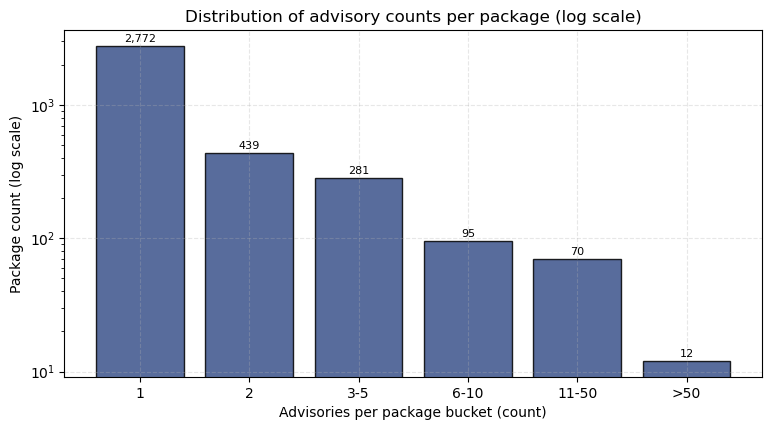

In [46]:
# fig_05: Bar chart of advisories per package bucket (log scale)
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(labels_p, b_counts_adv.values, color='#3b528b', edgecolor='black', alpha=0.85)
ax.set_yscale('log')
ax.set_ylabel('Package count (log scale)')
ax.set_xlabel('Advisories per package bucket (count)')
ax.set_title('Distribution of advisory counts per package (log scale)')
for i, v in enumerate(b_counts_adv.values):
    ax.annotate(f'{v:,}', xy=(i, v), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8)
ax.grid(True, linestyle='--', alpha=0.3)
plt.savefig(FIG / 'fig_05_advisories_per_package.png', bbox_inches='tight', dpi=150)
plt.show()

## Part C - Time
**Question:** How are vulnerability and malware advisories distributed over time across years, months, and quarters?
**How to read:** fig_01 plots monthly vulnerability advisories in linear and log scales. fig_02 displays annual vulnerability counts. fig_03 tracks quarterly severity proportions. fig_04 and corresponding tables show monthly and daily malware reporting volumes.

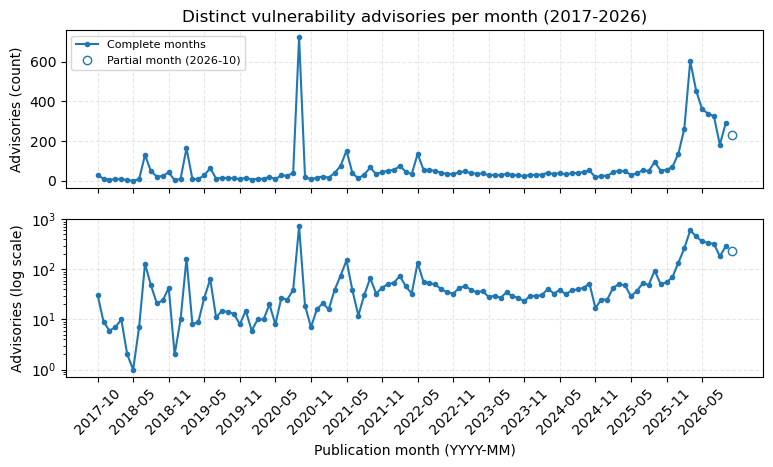

In [47]:
# fig_01: Distinct vulnerability advisories per month in linear and log scales
vuln_uniq = vuln.drop_duplicates('osv_id').copy()
vuln_uniq['month'] = vuln_uniq['published'].dt.tz_convert(None).dt.to_period('M')
m_counts = vuln_uniq[vuln_uniq.published.dt.year >= 2017].groupby('month')['osv_id'].count()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
x = [str(m) for m in m_counts.index]
y = m_counts.values

ax1.plot(x[:-1], y[:-1], marker='o', markersize=3, linestyle='-', color='#1f77b4', label='Complete months')
ax1.plot(x[-1:], y[-1:], marker='o', markerfacecolor='none', markeredgecolor='#1f77b4', markersize=6, linestyle='', label='Partial month (2026-10)')
ax1.set_ylabel('Advisories (count)')
ax1.set_title('Distinct vulnerability advisories per month (2017-2026)')
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.legend(loc='upper left', fontsize=8)

ax2.plot(x[:-1], y[:-1], marker='o', markersize=3, linestyle='-', color='#1f77b4')
ax2.plot(x[-1:], y[-1:], marker='o', markerfacecolor='none', markeredgecolor='#1f77b4', markersize=6, linestyle='')
ax2.set_yscale('log')
ax2.set_ylabel('Advisories (log scale)')
ax2.set_xlabel('Publication month (YYYY-MM)')
ax2.set_xticks(range(0, len(x), 6))
ax2.set_xticklabels([x[i] for i in range(0, len(x), 6)], rotation=45)
ax2.grid(True, linestyle='--', alpha=0.3)
plt.savefig(FIG / 'fig_01_monthly_vuln_advisories.png', bbox_inches='tight', dpi=150)
plt.show()

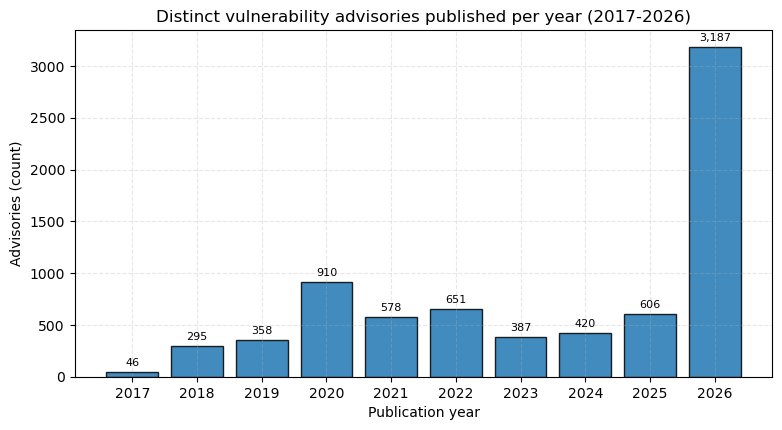

In [48]:
# fig_02: Distinct vulnerability advisories published per year (annotated bar chart)
year_counts = vuln_uniq[vuln_uniq.published.dt.year >= 2017]['published'].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(year_counts.index.astype(str), year_counts.values, color='#1f77b4', edgecolor='black', alpha=0.85)
for b in bars:
    h = b.get_height()
    ax.annotate(f'{h:,}', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                textcoords='offset points', ha='center', va='bottom', fontsize=8)
ax.set_ylabel('Advisories (count)')
ax.set_xlabel('Publication year')
ax.set_title('Distinct vulnerability advisories published per year (2017-2026)')
ax.grid(True, linestyle='--', alpha=0.3)
plt.savefig(FIG / 'fig_02_yearly_vuln_advisories.png', bbox_inches='tight', dpi=150)
plt.show()

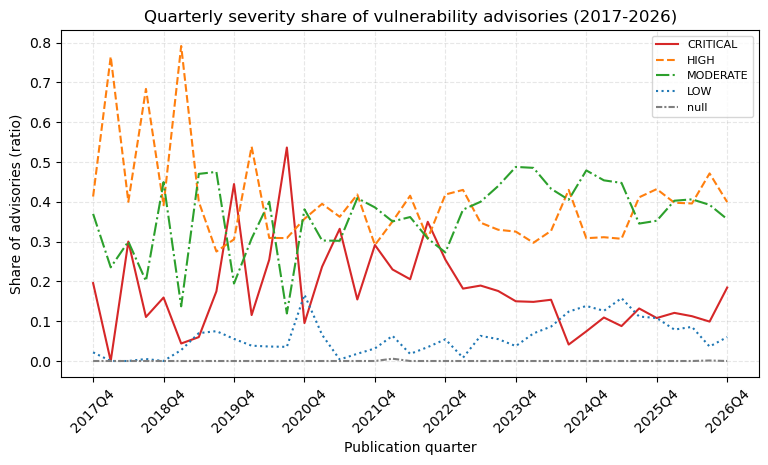

In [49]:
# fig_03: Severity share per quarter (CRITICAL, HIGH, MODERATE, LOW, null)
vuln_uniq['quarter'] = vuln_uniq['published'].dt.tz_convert(None).dt.to_period('Q')
sev_q = vuln_uniq[vuln_uniq.published.dt.year >= 2017].groupby(['quarter', vuln_uniq.severity.fillna('null')])['osv_id'].count().unstack(fill_value=0)
sev_q_share = sev_q.div(sev_q.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 4.5))
styles = {
    'CRITICAL': ('#d62728', '-'), 'HIGH': ('#ff7f0e', '--'),
    'MODERATE': ('#2ca02c', '-.'), 'LOW': ('#1f77b4', ':'), 'null': ('#7f7f7f', (0, (3, 1, 1, 1)))
}
qx = [str(q) for q in sev_q_share.index]
for col in ['CRITICAL', 'HIGH', 'MODERATE', 'LOW', 'null']:
    if col in sev_q_share.columns:
        c, ls = styles[col]
        ax.plot(qx, sev_q_share[col].values, label=col, color=c, linestyle=ls, linewidth=1.5)
ax.set_ylabel('Share of advisories (ratio)')
ax.set_xlabel('Publication quarter')
ax.set_title('Quarterly severity share of vulnerability advisories (2017-2026)')
ax.set_xticks(range(0, len(qx), 4))
ax.set_xticklabels([qx[i] for i in range(0, len(qx), 4)], rotation=45)
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(loc='upper right', fontsize=8)
plt.savefig(FIG / 'fig_03_severity_share_quarterly.png', bbox_inches='tight', dpi=150)
plt.show()

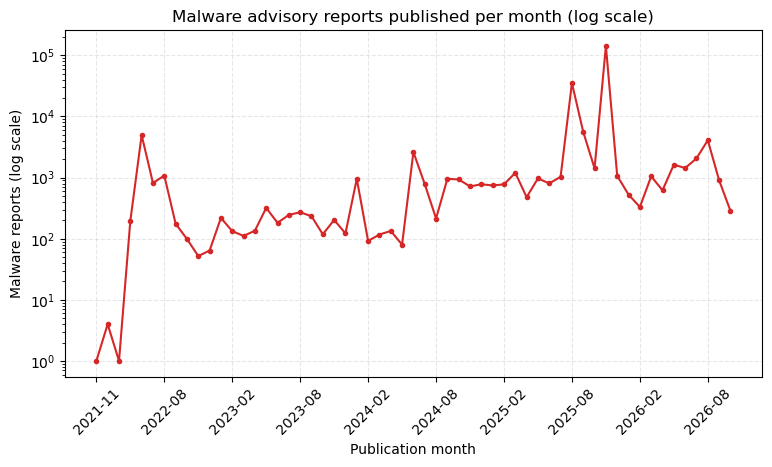

Top 10 months by malware reports:
          reports
month           
2025-11   142163
2025-08    35204
2025-09     5579
2022-06     4943
2026-08     4082
2024-06     2617
2026-07     2060
2026-05     1629
2026-06     1431
2025-10     1414

Top 10 days by malware reports:
             reports
day                
2025-11-11    76854
2025-11-12    46770
2025-08-14    34306
2025-11-10    11995
2025-11-13     5144
2025-09-05     4726
2022-06-20     4691
2024-06-25     2337
2026-08-05     1353
2026-08-28      958

Share of all malware reports published on top 5 busiest days: 0.7871


In [50]:
# fig_04: Monthly malware reports (log scale) and tables of top months and days
mal = adv[adv.kind == 'malware'].copy()
mal['month'] = mal['published'].dt.tz_convert(None).dt.to_period('M')
mal['day'] = mal['published'].dt.tz_convert(None).dt.to_period('D')
mal_m = mal.groupby('month')['osv_id'].count()

fig, ax = plt.subplots(figsize=(9, 4.5))
mx = [str(m) for m in mal_m.index]
ax.plot(mx, mal_m.values, marker='o', markersize=3, color='#d62728', linestyle='-')
ax.set_yscale('log')
ax.set_ylabel('Malware reports (log scale)')
ax.set_xlabel('Publication month')
ax.set_title('Malware advisory reports published per month (log scale)')
ax.set_xticks(range(0, len(mx), 6))
ax.set_xticklabels([mx[i] for i in range(0, len(mx), 6)], rotation=45)
ax.grid(True, linestyle='--', alpha=0.3)
plt.savefig(FIG / 'fig_04_monthly_malware_reports.png', bbox_inches='tight', dpi=150)
plt.show()

top_mal_months = mal.groupby('month')['osv_id'].count().nlargest(10).to_frame(name='reports')
top_mal_days = mal.groupby('day')['osv_id'].count().nlargest(10).to_frame(name='reports')
top5_day_share = top_mal_days.head(5)['reports'].sum() / len(mal)
print("Top 10 months by malware reports:\n", top_mal_months)
print("\nTop 10 days by malware reports:\n", top_mal_days)
print(f"\nShare of all malware reports published on top 5 busiest days: {top5_day_share:.4f}")

## Part D - The 2026 Surge
**Question:** How does advisory volume compare across the pre-surge and surge periods in terms of concentration, entrants, bursts, top packages, and persistence when top packages are excluded?
**How to read:** PRE_PERIOD ('2023-01-01', '2025-08-31') and SURGE_PERIOD ('2025-09-01', None) are visual annotations chosen from the monthly series, not empirical findings or causal claims. Tables and figures report quantitative counts and distributions without explanations or speculation.

In [51]:
# Period comparison: months, distinct advisories, and monthly means
print(f"PRE_PERIOD annotation: {PRE_PERIOD}")
print(f"SURGE_PERIOD annotation: {SURGE_PERIOD}")
print("Note: These comparison windows are visual annotations chosen from the monthly chart, not findings.\n")

vuln['month'] = vuln['published'].dt.tz_convert(None).dt.to_period('M')
vuln['day'] = vuln['published'].dt.tz_convert(None).dt.to_period('D')
pre_mask = (vuln.published >= PRE_PERIOD[0]) & (vuln.published <= PRE_PERIOD[1] + ' 23:59:59.999999+00:00')
surge_mask = vuln.published >= SURGE_PERIOD[0]

period_rows = []
for name, m in [('pre_period', pre_mask), ('surge_period', surge_mask)]:
    sub = vuln[m]
    period_rows.append({
        'period': name,
        'months_covered': sub['month'].nunique(),
        'distinct_advisories': sub['osv_id'].nunique(),
        'advisories_per_month_mean': sub.groupby('month')['osv_id'].nunique().mean(),
        'distinct_packages_per_month_mean': sub.groupby('month')['package'].nunique().mean(),
    })
df_periods = pd.DataFrame(period_rows)
print("Summary by period:\n", df_periods.to_string(index=False))

PRE_PERIOD annotation: ('2023-01-01', '2025-08-31')
SURGE_PERIOD annotation: ('2025-09-01', None)
Note: These comparison windows are visual annotations chosen from the monthly chart, not findings.

Summary by period:
       period  months_covered  distinct_advisories  advisories_per_month_mean  distinct_packages_per_month_mean
  pre_period              32                 1142                    35.6875                         33.625000
surge_period              14                 3458                   247.0000                        120.142857


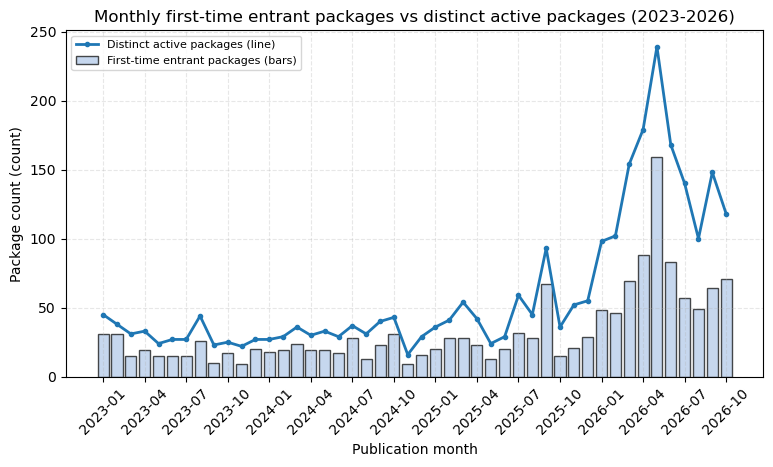

In [52]:
# fig_07: Monthly first-time entrant packages vs distinct active packages
first_vuln = vuln.groupby('package')['published'].min().dt.tz_convert(None).dt.to_period('M')
all_months = vuln['month'].drop_duplicates().sort_values()
all_months = all_months[all_months >= pd.Period(PRE_PERIOD[0][:7], 'M')]
entrants = first_vuln.value_counts().reindex(all_months, fill_value=0)
active_pkgs = vuln.groupby('month')['package'].nunique().reindex(all_months, fill_value=0)

fig, ax1 = plt.subplots(figsize=(9, 4.5))
x_str = [str(m) for m in all_months]
ax1.bar(x_str, entrants.values, color='#aec7e8', edgecolor='black', alpha=0.7, label='First-time entrant packages (bars)')
ax1.plot(x_str, active_pkgs.values, color='#1f77b4', marker='o', markersize=3, linestyle='-', linewidth=2, label='Distinct active packages (line)')
ax1.set_ylabel('Package count (count)')
ax1.set_xlabel('Publication month')
ax1.set_title('Monthly first-time entrant packages vs distinct active packages (2023-2026)')
ax1.set_xticks(range(0, len(x_str), 3))
ax1.set_xticklabels([x_str[i] for i in range(0, len(x_str), 3)], rotation=45)
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.legend(loc='upper left', fontsize=8)
plt.savefig(FIG / 'fig_07_monthly_entrants_vs_packages.png', bbox_inches='tight', dpi=150)
plt.show()

Surge advisory rows on packages with prior advisory (< 2025-09-01): 0.5115
Surge advisory rows on packages with NO prior advisory: 0.4885

Top-N concentration table:
   N  pre_period_top_N_share  surge_period_top_N_share
  1                0.054770                  0.113878
  5                0.148999                  0.266551
 10                0.196702                  0.336615
 20                0.253828                  0.415171
 50                0.363958                  0.540050
100                0.474676                  0.638680


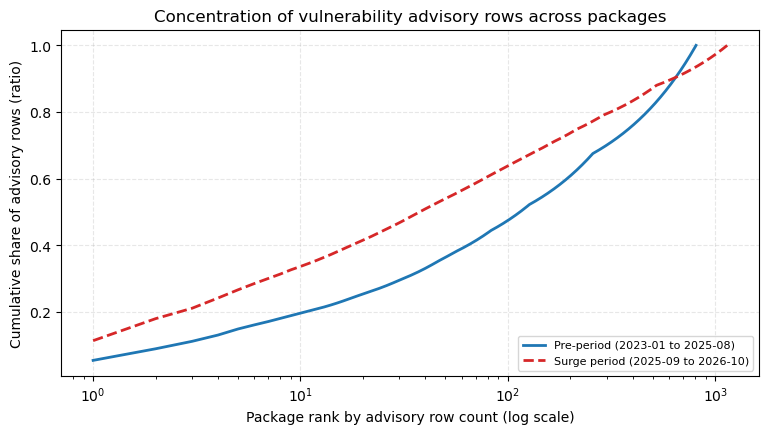

In [53]:
# Surge prior-package share, top-N concentration table, and fig_06 cumulative share curve
prior_pkgs = set(vuln[vuln.published < SURGE_PERIOD[0]]['package'])
surge_rows = vuln[surge_mask]
has_prior_pkg = surge_rows['package'].isin(prior_pkgs)
print(f"Surge advisory rows on packages with prior advisory (< {SURGE_PERIOD[0]}): {has_prior_pkg.mean():.4f}")
print(f"Surge advisory rows on packages with NO prior advisory: {(~has_prior_pkg).mean():.4f}\n")

conc_rows = []
for N in [1, 5, 10, 20, 50, 100]:
    conc_rows.append({
        'N': N,
        'pre_period_top_N_share': vuln[pre_mask]['package'].value_counts().head(N).sum() / len(vuln[pre_mask]),
        'surge_period_top_N_share': surge_rows['package'].value_counts().head(N).sum() / len(surge_rows),
    })
df_concentration = pd.DataFrame(conc_rows)
print("Top-N concentration table:\n", df_concentration.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, m, color, ls in [('Pre-period (2023-01 to 2025-08)', pre_mask, '#1f77b4', '-'),
                           ('Surge period (2025-09 to 2026-10)', surge_mask, '#d62728', '--')]:
    sub = vuln[m]
    counts = sub['package'].value_counts().values
    cum_share = np.cumsum(counts) / np.sum(counts)
    x = np.arange(1, len(cum_share) + 1)
    ax.plot(x, cum_share, label=name, color=color, linestyle=ls, linewidth=2)
ax.set_xscale('log')
ax.set_ylabel('Cumulative share of advisory rows (ratio)')
ax.set_xlabel('Package rank by advisory row count (log scale)')
ax.set_title('Concentration of vulnerability advisory rows across packages')
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(loc='lower right', fontsize=8)
plt.savefig(FIG / 'fig_06_concentration_cumulative_share.png', bbox_inches='tight', dpi=150)
plt.show()

Top 30 packages in surge period with pre-period counts:
                            surge_rows  pre_rows
package                                        
openclaw                          590         0
n8n                               342         9
parse-server                      162        21
electron                          159        32
next                              128        31
flowise                            98        16
axios                              78         5
undici                             69        17
vm2                                66         7
ghost                              52         7
@angular/platform-server           49         0
hono                               47         4
pnpm                               46         4
payload                            43         3
nocodb                             43         6
@budibase/server                   41         1
@angular/core                      37         0
fast-uri                       

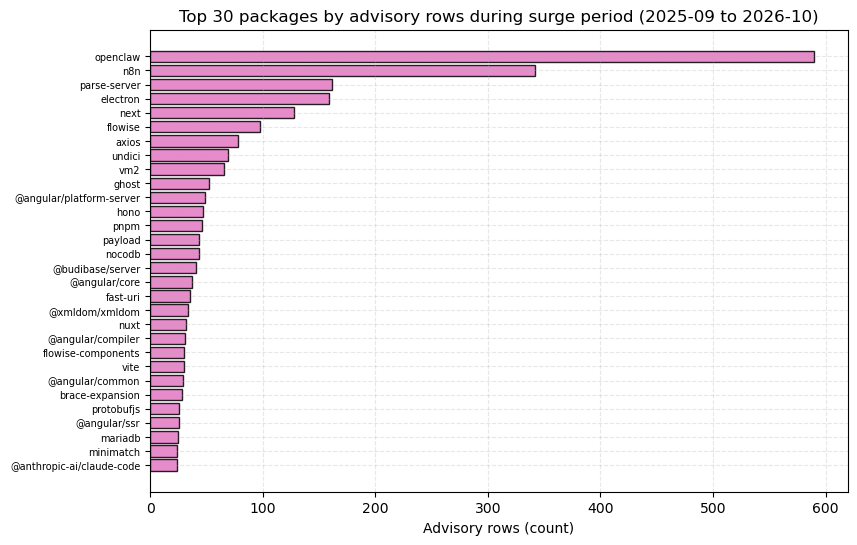

In [54]:
# fig_09: Horizontal bar chart of top 30 packages in surge period and pre-period comparison
surge_top30 = surge_rows['package'].value_counts().head(30)
pre_counts = vuln[pre_mask]['package'].value_counts()
df_top30 = pd.DataFrame({
    'surge_rows': surge_top30,
    'pre_rows': pre_counts.reindex(surge_top30.index).fillna(0).astype(int)
})
print("Top 30 packages in surge period with pre-period counts:\n", df_top30)

fig, ax = plt.subplots(figsize=(9, 6))
y_pos = np.arange(len(surge_top30))
ax.barh(y_pos, surge_top30.values[::-1], color='#e377c2', edgecolor='black', alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels(surge_top30.index[::-1], fontsize=7)
ax.set_xlabel('Advisory rows (count)')
ax.set_title('Top 30 packages by advisory rows during surge period (2025-09 to 2026-10)')
ax.grid(True, linestyle='--', alpha=0.3)
plt.savefig(FIG / 'fig_09_surge_top30_packages.png', bbox_inches='tight', dpi=150)
plt.show()

In [55]:
# Daily burstiness and month-by-month top package shares during the surge period
surge_days = surge_rows.groupby('day')['osv_id'].nunique().sort_values(ascending=False)
top10_days_share = surge_days.head(10).sum() / surge_rows['osv_id'].nunique()
print("Top 15 days by distinct advisories in surge period:\n", surge_days.head(15))
print(f"\nShare of surge advisories published on 10 busiest days: {top10_days_share:.4f}\n")

m_top_rows = []
for m, grp in surge_rows.groupby('month'):
    top_p = grp['package'].value_counts().index[0]
    top_cnt = grp['package'].value_counts().iloc[0]
    m_top_rows.append({
        'month': str(m), 'top_package': top_p, 'top_package_rows': top_cnt,
        'month_total_rows': len(grp), 'share': top_cnt / len(grp)
    })
df_m_top = pd.DataFrame(m_top_rows)
print("Month-by-month top package and share:\n", df_m_top.to_string(index=False))

Top 15 days by distinct advisories in surge period:
 day
2026-03-03    113
2026-10-07     93
2026-04-03     66
2026-04-16     64
2026-07-02     59
2026-06-18     57
2026-07-24     53
2026-07-22     49
2026-06-15     49
2026-10-05     47
2026-03-26     47
2026-03-02     47
2026-09-08     47
2026-05-14     46
2026-04-17     44
Freq: D, Name: osv_id, dtype: int64

Share of surge advisories published on 10 busiest days: 0.1880

Month-by-month top package and share:
   month top_package  top_package_rows  month_total_rows    share
2025-09        vite                 8               128 0.062500
2025-10     flowise                 8                70 0.114286
2025-11  tryton-sao                 8                97 0.082474
2025-12        next                36               157 0.229299
2026-01        next                27               223 0.121076
2026-02    openclaw                78               356 0.219101
2026-03    openclaw               272               764 0.356021
2026-04    op

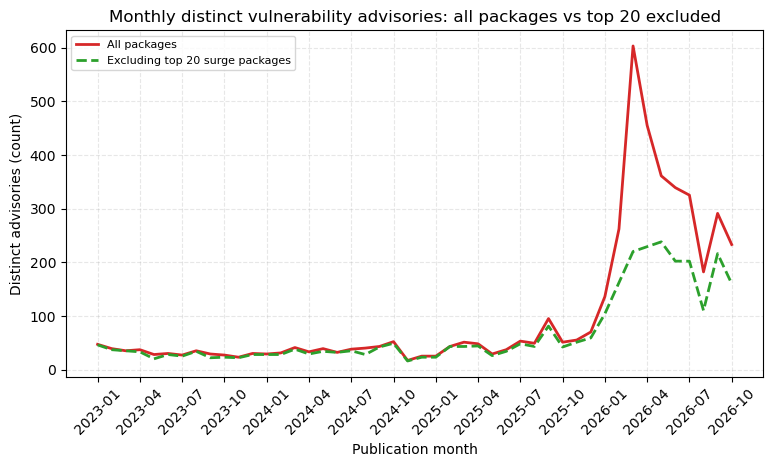

Surge period monthly mean (all packages): 247.00
Surge period monthly mean (excluding top 20 packages): 148.29


In [56]:
# fig_08: Monthly distinct advisories: all packages vs excluding top 20 surge packages
top20_surge_pkgs = surge_rows['package'].value_counts().head(20).index.tolist()
all_m = vuln.groupby('month')['osv_id'].nunique().reindex(all_months, fill_value=0)
ex20_m = vuln[~vuln.package.isin(top20_surge_pkgs)].groupby('month')['osv_id'].nunique().reindex(all_months, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x_str, all_m.values, color='#d62728', linestyle='-', linewidth=2, label='All packages')
ax.plot(x_str, ex20_m.values, color='#2ca02c', linestyle='--', linewidth=2, label='Excluding top 20 surge packages')
ax.set_ylabel('Distinct advisories (count)')
ax.set_xlabel('Publication month')
ax.set_title('Monthly distinct vulnerability advisories: all packages vs top 20 excluded')
ax.set_xticks(range(0, len(x_str), 3))
ax.set_xticklabels([x_str[i] for i in range(0, len(x_str), 3)], rotation=45)
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(loc='upper left', fontsize=8)
plt.savefig(FIG / 'fig_08_surge_top20_exclusion.png', bbox_inches='tight', dpi=150)
plt.show()

surge_period_months = pd.period_range(SURGE_PERIOD[0][:7], all_months.max(), freq='M')
print(f"Surge period monthly mean (all packages): {all_m.reindex(surge_period_months).mean():.2f}")
print(f"Surge period monthly mean (excluding top 20 packages): {ex20_m.reindex(surge_period_months).mean():.2f}")

In [57]:
# Severity mix and id-prefix mix comparisons: pre-period vs surge period
sev_pre = vuln[pre_mask]['severity'].fillna('null').value_counts(normalize=True).rename('pre_share')
sev_surge = vuln[surge_mask]['severity'].fillna('null').value_counts(normalize=True).rename('surge_share')
df_sev_mix = pd.concat([sev_pre, sev_surge], axis=1).fillna(0)
print("Severity mix (pre vs surge):\n", df_sev_mix)

pref_pre = vuln[pre_mask]['osv_id'].str.split('-').str[0].value_counts(normalize=True).rename('pre_share')
pref_surge = vuln[surge_mask]['osv_id'].str.split('-').str[0].value_counts(normalize=True).rename('surge_share')
df_pref_mix = pd.concat([pref_pre, pref_surge], axis=1).fillna(0)
print("\nId-prefix mix (pre vs surge):\n", df_pref_mix)

Severity mix (pre vs surge):
           pre_share  surge_share
severity                        
MODERATE   0.421084     0.366918
HIGH       0.383981     0.437367
CRITICAL   0.113074     0.128547
LOW        0.081861     0.066975
null       0.000000     0.000193

Id-prefix mix (pre vs surge):
         pre_share  surge_share
osv_id                        
GHSA          1.0     0.999807
EEF           0.0     0.000193


## Surge Analysis Scope: What the Data Can and Cannot Distinguish

- **Concentrated in few packages vs broad?**
  - The top-N shares and Lorenz-style cumulative curves distinguish whether advisory rows are concentrated in a few packages (e.g. top 20 holding 41.5% of surge rows) versus dispersed across thousands of packages.
- **Bursty vs steady?**
  - Daily time series and 10-day burst shares distinguish whether advisories arrived in isolated single-day dumps or continuously across consecutive months.
- **New vs repeat packages?**
  - Historical lookup distinguishes whether surge advisories target packages with prior advisory history (51.1% of rows) or first-time entrants (48.9% of rows).
- **Persistence without top packages?**
  - Filtering out the 20 most affected packages reveals whether monthly advisory rates remain elevated (mean 148.3/mo) compared to pre-period baseline (mean 35.7/mo).
- **What this analysis CANNOT distinguish:**
  - The underlying drivers (e.g. changes in security researcher tooling, targeted audits, automated scanning bots, registry reporting rules, or disclosure pipelines) are external to the OSV dataset and cannot be established from advisory timestamps alone. No causal explanation is asserted.

## Part E - Label Windows and Splits
**Question:** How do the planned label windows and temporal splits behave in terms of positive counts, embargo adherence, consecutive window overlap, and horizon sensitivity?
**How to read:** Tables report snapshot dates, split assignments, positive counts, repeat rates, and Jaccard overlap between consecutive monthly dates. Note: base rates within the modelling universe cannot be computed here because the package universe is constructed from deps.dev in subsequent stages.

In [58]:
# Build monthly grid, assign splits, apply 6-month embargo, and assert separation
grid = monthly_grid(snaps.Time)
print(f"Grid size: {len(grid)} snapshot dates")

s = assign_splits(grid)
print("Dates per split before embargo:\n", s.split.value_counts())

s2, dropped = apply_embargo(s)
print("\nDates per split after embargo:\n", s2.split.value_counts())
print("\nDropped dates during embargo filtering:", dropped)

order = ('train', 'val', 'test_a', 'test_b')
for prev, nxt in zip(order, order[1:]):
    prev_max = s2.loc[s2.split == prev, 'T'].max()
    nxt_min = s2.loc[s2.split == nxt, 'T'].min()
    limit = (prev_max + pd.DateOffset(months=HORIZON_MONTHS)).date()
    assert nxt_min.date() > limit, f"Embargo violated between {prev} and {nxt}"
print("Confirmed: Embargo property holds for all consecutive splits.")

Grid size: 40 snapshot dates
Dates per split before embargo:
 split
train     13
test_b     6
val        3
test_a     3
Name: count, dtype: int64

Dates per split after embargo:
 split
train     13
test_b     6
test_a     3
val        2
Name: count, dtype: int64

Dropped dates during embargo filtering: [Timestamp('2024-07-01 21:00:42.720159+0000', tz='UTC')]
Confirmed: Embargo property holds for all consecutive splits.


In [59]:
# Compute label_counts for each embargoed snapshot date and summarize per split
records = []
for idx, row in s2.iterrows():
    lc = label_counts(adv, row['T'])
    rec = {**row.to_dict(), **lc}
    rec['repeat_rate'] = rec['repeat_positives'] / rec['packages_with_prior_advisory'] if rec['packages_with_prior_advisory'] > 0 else 0.0
    records.append(rec)
df_labels = pd.DataFrame(records)
print("Label counts table (sample rows):\n", df_labels[['target_month', 'split', 'positive_packages', 'first_time_positives', 'repeat_positives', 'repeat_rate']].head())

split_summary = df_labels.groupby('split')['positive_packages'].agg(
    n_dates='count', total='sum', min='min', median='median', max='max'
)
print("\nPer-split summary of positive packages:\n", split_summary)

low_dates = df_labels[df_labels['positive_packages'] < 30]
if len(low_dates) == 0:
    print("\nFlag: No dates have fewer than 30 positive packages.")
else:
    print("\nFlag: Dates with fewer than 30 positives:\n", low_dates[['target_month', 'split', 'positive_packages']])

Label counts table (sample rows):
   target_month  split  positive_packages  first_time_positives  \
0      2023-01  train                185                   125   
1      2023-02  train                171                   114   
2      2023-03  train                161                   104   
3      2023-04  train                160                   101   
4      2023-05  train                155                    98   

   repeat_positives  repeat_rate  
0                60     0.027868  
1                57     0.026159  
2                57     0.025757  
3                59     0.026469  
4                57     0.025356  

Per-split summary of positive packages:
         n_dates  total  min  median  max
split                                   
test_a        3    742  218   256.0  268
test_b        6   4057  495   722.5  748
train        13   2083  143   157.0  185
val           2    351  171   175.5  180

Flag: No dates have fewer than 30 positive packages.


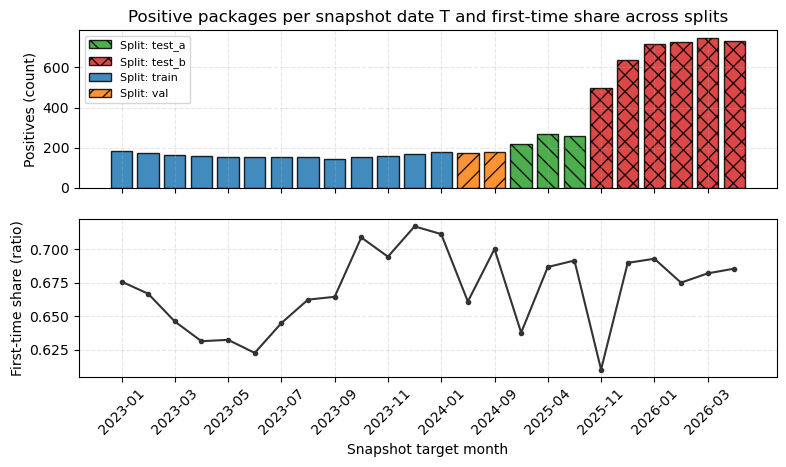

In [60]:
# fig_10: Positives per T by split and first-time positive share (stacked panels)
df_labels['first_time_share'] = df_labels['first_time_positives'] / df_labels['positive_packages']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
split_colors = {'train': '#1f77b4', 'val': '#ff7f0e', 'test_a': '#2ca02c', 'test_b': '#d62728'}
split_hatches = {'train': '', 'val': '//', 'test_a': '\\\\', 'test_b': 'xx'}

x_idx = np.arange(len(df_labels))
x_labels = df_labels['target_month'].tolist()
for sp, grp in df_labels.groupby('split'):
    idxs = grp.index.values
    ax1.bar(idxs, grp['positive_packages'], color=split_colors[sp], hatch=split_hatches[sp],
            edgecolor='black', alpha=0.85, label=f'Split: {sp}')
ax1.set_ylabel('Positives (count)')
ax1.set_title('Positive packages per snapshot date T and first-time share across splits')
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.legend(loc='upper left', fontsize=8)

ax2.plot(x_idx, df_labels['first_time_share'], marker='o', markersize=3, color='#333333', linestyle='-')
ax2.set_ylabel('First-time share (ratio)')
ax2.set_xlabel('Snapshot target month')
ax2.set_xticks(range(0, len(x_labels), 2))
ax2.set_xticklabels([x_labels[i] for i in range(0, len(x_labels), 2)], rotation=45)
ax2.grid(True, linestyle='--', alpha=0.3)
plt.savefig(FIG / 'fig_10_positives_and_first_time_share_by_T.png', bbox_inches='tight', dpi=150)
plt.show()

Consecutive snapshot overlap table:
      split              pair   jaccard
0    train  2023-01->2023-02  0.728155
1    train  2023-02->2023-03  0.635468
2    train  2023-03->2023-04  0.716578
3    train  2023-04->2023-05  0.750000
4    train  2023-05->2023-06  0.800000
5    train  2023-06->2023-07  0.731429
6    train  2023-07->2023-08  0.771930
7    train  2023-08->2023-09  0.670455
8    train  2023-09->2023-10  0.680000
9    train  2023-10->2023-11  0.760000
10   train  2023-11->2023-12  0.745946
11   train  2023-12->2024-01  0.704433
12     val  2024-08->2024-09  0.695652
13  test_a  2025-03->2025-04  0.625418
14  test_a  2025-04->2025-05  0.825784
15  test_b  2025-11->2025-12  0.678519
16  test_b  2025-12->2026-01  0.829730
17  test_b  2026-01->2026-02  0.871762
18  test_b  2026-02->2026-03  0.818966
19  test_b  2026-03->2026-04  0.810282

Median Jaccard overlap per split:
 split
test_a    0.725601
test_b    0.818966
train     0.729792
val       0.695652
Name: jaccard, dtype: floa

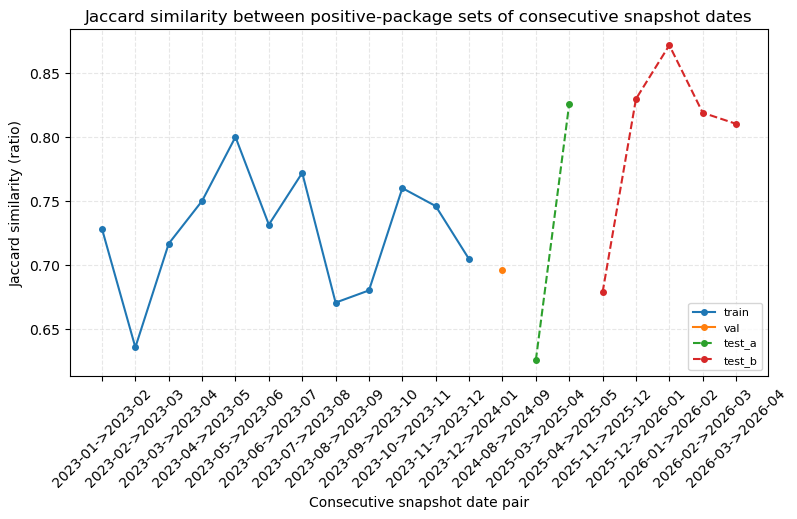

In [61]:
# fig_11: Consecutive monthly date positive-package overlap (Jaccard similarity)
overlap_rows = []
d_vuln = adv[(adv.kind == 'vulnerability') & adv.withdrawn.isna() & adv.published.notna()]
for split_name, grp in df_labels.groupby('split', sort=False):
    grp_sorted = grp.sort_values('T').reset_index(drop=True)
    for i in range(len(grp_sorted) - 1):
        t1, t2 = grp_sorted.loc[i, 'T'], grp_sorted.loc[i+1, 'T']
        m1, m2 = grp_sorted.loc[i, 'target_month'], grp_sorted.loc[i+1, 'target_month']
        pos1 = set(d_vuln[(d_vuln.published > t1) & (d_vuln.published <= t1 + pd.DateOffset(months=HORIZON_MONTHS))].package)
        pos2 = set(d_vuln[(d_vuln.published > t2) & (d_vuln.published <= t2 + pd.DateOffset(months=HORIZON_MONTHS))].package)
        jaccard = len(pos1 & pos2) / len(pos1 | pos2) if len(pos1 | pos2) > 0 else 0.0
        overlap_rows.append({'split': split_name, 'pair': f'{m1}->{m2}', 'jaccard': jaccard})
df_overlap = pd.DataFrame(overlap_rows)
print("Consecutive snapshot overlap table:\n", df_overlap)
print("\nMedian Jaccard overlap per split:\n", df_overlap.groupby('split')['jaccard'].median())

fig, ax = plt.subplots(figsize=(9, 4.5))
for sp, grp in df_overlap.groupby('split', sort=False):
    ax.plot(grp.index, grp['jaccard'], marker='o', markersize=4, label=sp,
            color=split_colors[sp], linestyle='--' if 'test' in sp else '-')
ax.set_ylabel('Jaccard similarity (ratio)')
ax.set_xlabel('Consecutive snapshot date pair')
ax.set_title('Jaccard similarity between positive-package sets of consecutive snapshot dates')
ax.set_xticks(range(len(df_overlap)))
ax.set_xticklabels(df_overlap['pair'], rotation=45)
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(loc='lower right', fontsize=8)
plt.savefig(FIG / 'fig_11_split_consecutive_overlap_jaccard.png', bbox_inches='tight', dpi=150)
plt.show()

In [62]:
# Horizon sensitivity analysis (3, 6, 12 months) at the five reconciliation dates
latest_snap = snaps.Time.max()
def label_counts_h(adv_df, T, horizon):
    end = T + pd.DateOffset(months=horizon)
    if end > latest_snap: return None
    d = adv_df[(adv_df.kind == 'vulnerability') & adv_df.withdrawn.isna() & adv_df.published.notna()]
    win = d[(d.published > T) & (d.published <= end)]
    pos, prior = set(win.package), set(d[d.published <= T].package)
    return {'T': str(T)[:10], 'horizon_months': horizon, 'positive_packages': len(pos), 'first_time_positives': len(pos - prior)}

sens_rows = []
for t_str, _, _, _, _, _ in reconcile_label_dates:
    for h in [3, 6, 12]:
        res = label_counts_h(adv, pd.Timestamp(t_str), h)
        if res is not None:
            sens_rows.append(res)
df_sens = pd.DataFrame(sens_rows)
print("Horizon sensitivity (3, 6, 12 months):\n", df_sens.to_string(index=False))

Horizon sensitivity (3, 6, 12 months):
          T  horizon_months  positive_packages  first_time_positives
2024-01-01               3                 89                    61
2024-01-01               6                180                   128
2024-01-01              12                320                   236
2024-07-01               3                 92                    54
2024-07-01               6                162                   108
2024-07-01              12                334                   241
2024-12-30               3                122                    75
2024-12-30               6                204                   132
2024-12-30              12                454                   323
2025-06-30               3                191                   127
2025-06-30               6                299                   191
2025-06-30              12                924                   685
2025-12-29               3                300                   165
2025-12-

## Note on Base Rate
The positive counts reported here encompass all packages in npm receiving an OSV advisory. The true modeling base rate cannot be calculated here because the package universe (`universe_T`, defined as the top 30,000 packages by declared dependents as of date T) is created from BigQuery `NPMRequirements` in pipeline Stage 3.

## Part F - Matcher Readiness
**Question:** Are the OSV affected-version ranges and version strings clean enough for the planned version matcher (docs/05 section 4)? What odd cases exist?
**How to read:** Reports strict semver parsing adherence, range types, event kinds, and interval structures across vulnerability rows and a 20,000-row sample of malware rows. fig_12 summarizes range types and event patterns.

In [63]:
# Strict SemVer validator and OSV range/version structure analyzer
import re

try:
    from semantic_version import Version
    def is_semver(v):
        if str(v) == '0': return True
        try: Version(str(v)); return True
        except ValueError: return False
    print("Using semantic_version.Version for SemVer validation.")
except ImportError:
    SEMVER_REGEX = re.compile(
        r'^(0|[1-9]\d*)\.(0|[1-9]\d*)\.(0|[1-9]\d*)'
        r'(?:-((?:0|[1-9]\d*|\d*[a-zA-Z-][0-9a-zA-Z-]*)(?:\.(?:0|[1-9]\d*|\d*[a-zA-Z-][0-9a-zA-Z-]*))*))?'
        r'(?:\+([0-9a-zA-Z-]+(?:\.[0-9a-zA-Z-]+)*))?$'
    )
    def is_semver(v):
        if str(v) == '0': return True
        return bool(SEMVER_REGEX.match(str(v)))
    print("Using strict-semver regex fallback for SemVer validation.")

def parse_matcher_records(df):
    records = []
    for row in df[['osv_id', 'ranges_json', 'versions_json']].itertuples(index=False):
        r_list = json.loads(row.ranges_json) if row.ranges_json else []
        v_list = json.loads(row.versions_json) if row.versions_json else []
        records.append((row.osv_id, r_list, v_list))
    return records

vuln_records = parse_matcher_records(vuln)
mal_sample = adv[(adv.kind == 'malware') & adv.withdrawn.isna()].sample(20000, random_state=SEED)
mal_records = parse_matcher_records(mal_sample)
print(f"Prepared {len(vuln_records)} vuln records and {len(mal_records)} malware records.")

Using strict-semver regex fallback for SemVer validation.
Prepared 10169 vuln records and 20000 malware records.


In [64]:
# Compute matcher readiness statistics and inspect unusual rows for vulnerabilities
def evaluate_matcher(records, name):
    no_rng_no_ver = sum(1 for _, r, v in records if not r and not v)
    only_ver = sum(1 for _, r, v in records if not r and v)
    range_types, event_kinds = {}, {}
    ranges_start_0, ranges_with_fixed, ranges_with_last_aff = 0, 0, 0
    total_ranges, unparseable = 0, []
    intervals_per_range, ver_lengths, matchable = [], [], 0
    unusual = []
    for oid, r_list, v_list in records:
        all_semver = True
        if v_list: ver_lengths.append(len(v_list))
        for v in v_list:
            if not is_semver(v): all_semver = False; unparseable.append((oid, 'versions', str(v)))
        for r in r_list:
            total_ranges += 1
            t = r.get('type', 'missing'); range_types[t] = range_types.get(t, 0) + 1
            evs = r.get('events', [])
            intervals_per_range.append(sum(1 for e in evs if 'introduced' in e))
            if evs and evs[0].get('introduced') == '0': ranges_start_0 += 1
            if any('fixed' in e for e in evs): ranges_with_fixed += 1
            if any('last_affected' in e for e in evs): ranges_with_last_aff += 1
            for e in evs:
                for k, v in e.items():
                    event_kinds[k] = event_kinds.get(k, 0) + 1
                    if not is_semver(v): all_semver = False; unparseable.append((oid, k, str(v)))
        if (r_list or v_list) and all_semver: matchable += 1
        if len(r_list) > 1 or any(r.get('type') not in ('SEMVER', 'ECOSYSTEM') for r in r_list):
            unusual.append((oid, r_list))
    return {
        'name': name, 'total_rows': len(records), 'unmatchable_share': no_rng_no_ver / len(records),
        'only_versions_rows': only_ver, 'range_types': range_types, 'event_kinds': event_kinds,
        'share_start_0': ranges_start_0 / total_ranges if total_ranges else 0,
        'share_fixed': ranges_with_fixed / total_ranges if total_ranges else 0,
        'share_last_affected': ranges_with_last_aff / total_ranges if total_ranges else 0,
        'intervals_counts': pd.Series(intervals_per_range).value_counts().to_dict(),
        'versions_len_desc': pd.Series(ver_lengths).describe().to_dict() if ver_lengths else {},
        'unparseable_strings': unparseable, 'matchable_rows': matchable, 'matchable_share': matchable / len(records),
        'unusual_rows': unusual
    }

In [65]:
# Evaluate matcher readiness on vulnerabilities and print unparseable/unusual cases
metrics_vuln = evaluate_matcher(vuln_records, 'vulnerability')
print(f"Matchability summary (vuln): {metrics_vuln['matchable_rows']}/{metrics_vuln['total_rows']} rows ({metrics_vuln['matchable_share']:.4%}) have valid semver and ranges/versions.")
print("Unparseable version strings count:", len(metrics_vuln['unparseable_strings']))
print("First 15 unparseable strings:\n", metrics_vuln['unparseable_strings'][:15])
print("\nUnusual rows count (multiple ranges or non-standard types):", len(metrics_vuln['unusual_rows']))
print("Sample unusual rows:\n", metrics_vuln['unusual_rows'][:5])

Matchability summary (vuln): 10135/10169 rows (99.6657%) have valid semver and ranges/versions.
Unparseable version strings count: 33
First 15 unparseable strings:
 [('GHSA-3h52-269p-cp9r', 'introduced', '13.0'), ('GHSA-4w6r-5c2j-qf5f', 'fixed', '2026.04.1'), ('GHSA-6xcx-7qmg-vjfq', 'fixed', '2026.04.1'), ('GHSA-8m45-2rjm-j347', 'introduced', '1.90'), ('GHSA-8m45-2rjm-j347', 'introduced', '1.89'), ('GHSA-8m45-2rjm-j347', 'introduced', '1.78'), ('GHSA-8m45-2rjm-j347', 'introduced', '1.77'), ('GHSA-8m7c-hf24-5g47', 'fixed', '2026.05.1'), ('GHSA-96fh-m4r8-6v9v', 'fixed', '2026.05.1'), ('GHSA-9g4f-5rpg-4948', 'fixed', '0.70'), ('GHSA-9wgh-m22w-9xj8', 'fixed', '2026.05.1'), ('GHSA-cmxg-94mg-jq94', 'fixed', '20260509.0340.15'), ('GHSA-cxv7-gmmp-228p', 'fixed', '2026.04.1'), ('GHSA-fw5f-7c6c-3vmv', 'fixed', '8.0'), ('GHSA-g72g-r7m4-9x4g', 'fixed', '2026.05.1')]

Unusual rows count (multiple ranges or non-standard types): 1
Sample unusual rows:
 [('EEF-CVE-2026-56812', [{'type': 'SEMVER', 'eve

Matchability summary (malware 20k sample): 20000/20000 rows (100.0000%) have valid semver and ranges/versions.


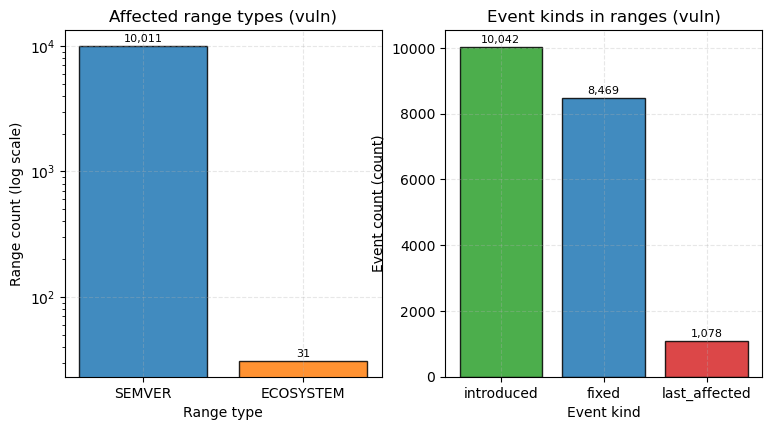

In [66]:
# fig_12: Range types and event patterns in vulnerability advisories
metrics_mal = evaluate_matcher(mal_records, 'malware (sample 20k)')
print(f"Matchability summary (malware 20k sample): {metrics_mal['matchable_rows']}/{metrics_mal['total_rows']} rows ({metrics_mal['matchable_share']:.4%}) have valid semver and ranges/versions.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.5))
r_types = metrics_vuln['range_types']
ax1.bar(list(r_types.keys()), list(r_types.values()), color=['#1f77b4', '#ff7f0e'], edgecolor='black', alpha=0.85)
ax1.set_ylabel('Range count (log scale)')
ax1.set_xlabel('Range type')
ax1.set_title('Affected range types (vuln)')
ax1.set_yscale('log')
ax1.grid(True, linestyle='--', alpha=0.3)
for i, (k, v) in enumerate(r_types.items()):
    ax1.annotate(f'{v:,}', xy=(i, v), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8)

e_kinds = metrics_vuln['event_kinds']
ax2.bar(list(e_kinds.keys()), list(e_kinds.values()), color=['#2ca02c', '#1f77b4', '#d62728'], edgecolor='black', alpha=0.85)
ax2.set_ylabel('Event count (count)')
ax2.set_xlabel('Event kind')
ax2.set_title('Event kinds in ranges (vuln)')
ax2.grid(True, linestyle='--', alpha=0.3)
for i, (k, v) in enumerate(e_kinds.items()):
    ax2.annotate(f'{v:,}', xy=(i, v), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8)
plt.savefig(FIG / 'fig_12_matcher_range_types_event_patterns.png', bbox_inches='tight', dpi=150)
plt.show()

## Part G - Demo Lockfile Candidates (Name-Level Matching)
**Question:** Which sample lockfile makes the best demo candidate for showcasing advisory exposures?
**How to read:** Tables report total, dev-only, and production installed packages and counts of name-level matches to known advisories. fig_13 compares production advisory matches across the five sample files.
**Caution:** Name-level matching overstates actual exposure because specific version requirements are not evaluated. Packages are flagged if any advisory exists anywhere in OSV for that package name. The version-aware matcher is developed in prompt P9.

In [67]:
# Parse sample lockfiles and compute installed, production, and name-level advisory matches
vuln_pkgs = set(vuln['package'])
mal_pkgs = set(adv[(adv.kind == 'malware') & adv.withdrawn.isna()]['package'])

sample_dir = DATA / 'sample_lockfiles'
lockfiles = sorted(sample_dir.glob('*.json'))
lock_rows = []
prod_adv_details = {}

for p in lockfiles:
    with open(p, 'r', encoding='utf-8') as f:
        data = json.load(f)
    installed_pkgs = {}
    for k, v in data.get('packages', {}).items():
        if k == '' or v.get('link') is True: continue
        name = v.get('name') or (k.split('node_modules/')[-1] if 'node_modules/' in k else k)
        is_dev = bool(v.get('dev', False))
        if name not in installed_pkgs: installed_pkgs[name] = {'dev': is_dev}
        elif not is_dev: installed_pkgs[name]['dev'] = False
    
    prod_pkgs = set(k for k, v in installed_pkgs.items() if not v['dev'])
    all_pkgs = set(installed_pkgs.keys())
    lock_rows.append({
        'lockfile': p.name, 'installed_packages': len(installed_pkgs),
        'dev_only': sum(1 for v in installed_pkgs.values() if v['dev']),
        'production': len(prod_pkgs), 'vuln_all': len(all_pkgs & vuln_pkgs),
        'malware_all': len(all_pkgs & mal_pkgs), 'vuln_prod': len(prod_pkgs & vuln_pkgs),
        'malware_prod': len(prod_pkgs & mal_pkgs)
    })
    prod_adv_details[p.name] = vuln[vuln.package.isin(prod_pkgs)]['package'].value_counts().head(15)

df_lockfiles = pd.DataFrame(lock_rows)
print("Sample lockfiles summary:\n", df_lockfiles.to_string(index=False))

Sample lockfiles summary:
               lockfile  installed_packages  dev_only  production  vuln_all  malware_all  vuln_prod  malware_prod
      arcane-demo.json                 201       150          51        33           13         12             7
       digitalgov.json                 844       203         641        89           23         69            17
expressjs-website.json                 881       391         490        72           18         42             4
        modernweb.json                1746       410        1336       171           23        140            20
             wger.json                 229       224           5        36            5          2             0



Top production packages with advisory rows in arcane-demo.json:
 package
brace-expansion     33
minimatch           26
debug                7
ejs                  5
follow-redirects     5
ms                   2
esbuild              2
http-proxy           2
async                2
color-name           1
fsevents             1
color-convert        1
Name: count, dtype: int64

Top production packages with advisory rows in digitalgov.json:
 package
@xmldom/xmldom          38
tar                     34
brace-expansion         33
minimatch               26
js-yaml                 17
fast-xml-parser         17
svgo                    12
lodash                  10
nanoid                   9
postcss                  9
immutable                9
debug                    7
picomatch                6
serialize-javascript     6
bl                       6
Name: count, dtype: int64

Top production packages with advisory rows in expressjs-website.json:
 package
undici             91
vite              

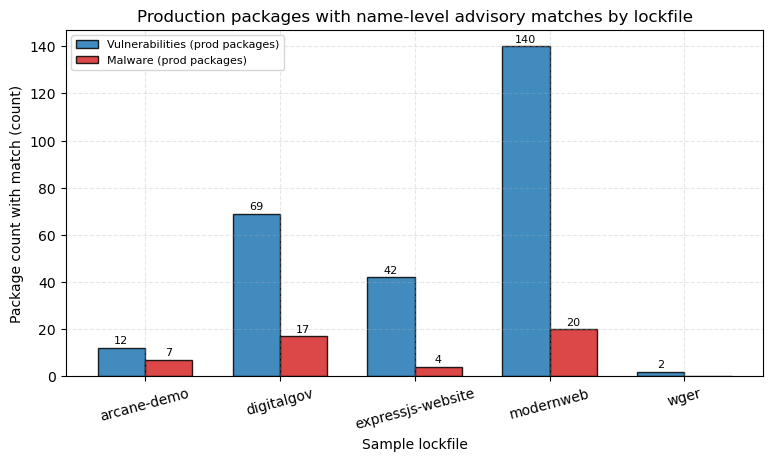

In [68]:
# fig_13: Production packages with name-level advisory matches by lockfile
for fname, top_p in prod_adv_details.items():
    print(f"\nTop production packages with advisory rows in {fname}:\n", top_p)

fig, ax = plt.subplots(figsize=(9, 4.5))
x_pos = np.arange(len(df_lockfiles))
w = 0.35
short_names = [f.replace('.json', '') for f in df_lockfiles['lockfile']]
b1 = ax.bar(x_pos - w/2, df_lockfiles['vuln_prod'], width=w, label='Vulnerabilities (prod packages)', color='#1f77b4', edgecolor='black', alpha=0.85)
b2 = ax.bar(x_pos + w/2, df_lockfiles['malware_prod'], width=w, label='Malware (prod packages)', color='#d62728', edgecolor='black', alpha=0.85)
ax.set_ylabel('Package count with match (count)')
ax.set_xlabel('Sample lockfile')
ax.set_title('Production packages with name-level advisory matches by lockfile')
ax.set_xticks(x_pos)
ax.set_xticklabels(short_names, rotation=15)
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(loc='upper left', fontsize=8)
for b in list(b1) + list(b2):
    h = b.get_height()
    if h > 0:
        ax.annotate(f'{h}', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                    textcoords='offset points', ha='center', fontsize=8)
plt.savefig(FIG / 'fig_13_lockfiles_prod_advisory_matches.png', bbox_inches='tight', dpi=150)
plt.show()

## Part H - Summary and Findings Template
**Question:** Export computed metrics to interim summary JSON, list generated figures, and tally reconciliation outcomes.

In [69]:
# Export computed summary variables to JSON and inspect output size
summary_data = {
    'counts_by_year': {str(k): int(v) for k, v in vuln_year.items()},
    'monthly_counts': {str(k): int(v) for k, v in m_counts.items()},
    'concentration_pre': {f"top_{r['N']}": float(r['pre_period_top_N_share']) for _, r in df_concentration.iterrows()},
    'concentration_surge': {f"top_{r['N']}": float(r['surge_period_top_N_share']) for _, r in df_concentration.iterrows()},
    'per_split_labels': [
        {
            'target_month': r['target_month'], 'split': r['split'], 'T': str(r['T']),
            'window_end': str(r['window_end']), 'advisories_in_window': int(r['advisories_in_window']),
            'positive_packages': int(r['positive_packages']), 'first_time_positives': int(r['first_time_positives']),
            'repeat_positives': int(r['repeat_positives']), 'repeat_rate': float(r['repeat_rate'])
        }
        for _, r in df_labels.iterrows()
    ],
    'matcher_readiness': {
        'vuln_matchable_share': float(metrics_vuln['matchable_share']),
        'vuln_unparseable_strings_count': len(metrics_vuln['unparseable_strings']),
        'malware_sample_matchable_share': float(metrics_mal['matchable_share'])
    },
    'lockfiles': df_lockfiles.to_dict(orient='records'),
    'reconciliation_results': [
        {'name': r[0], 'actual': str(r[1]) if isinstance(r[1], (pd.Timestamp, pd.Timedelta)) else r[1],
         'expected': str(r[2]) if isinstance(r[2], (pd.Timestamp, pd.Timedelta)) else r[2], 'ok': bool(r[3])}
        for r in RESULTS
    ]
}

def to_serializable(obj):
    if isinstance(obj, (np.integer, int)): return int(obj)
    if isinstance(obj, (np.floating, float)): return float(obj)
    if isinstance(obj, (np.bool_, bool)): return bool(obj)
    if isinstance(obj, (pd.Timestamp, pd.Timedelta)): return str(obj)
    raise TypeError(f"Type {type(obj)} not serializable")

out_json = DATA / 'interim' / 'eda_advisories_summary.json'
with open(out_json, 'w', encoding='utf-8') as f:
    json.dump(summary_data, f, indent=2, default=to_serializable)
print(f"Summary JSON written to: {out_json}")
print(f"File size: {out_json.stat().st_size:,} bytes")

Summary JSON written to: D:\DepRadar\data\interim\eda_advisories_summary.json
File size: 21,075 bytes


In [70]:
# Report inventory of saved figures and reconciliation PASS/FAIL summary
figures = sorted(FIG.glob('fig_*.png'))
print(f"Generated figures count: {len(figures)} in {FIG}")
for f in figures:
    print(f"  {f.name} ({f.stat().st_size / 1024:.1f} KB)")

pass_count = sum(1 for r in RESULTS if r[3])
fail_count = sum(1 for r in RESULTS if not r[3])
print(f"\nReconciliation checks: {pass_count} PASSED, {fail_count} FAILED (total {len(RESULTS)})")

Generated figures count: 13 in D:\DepRadar\docs\figures\eda_advisories
  fig_01_monthly_vuln_advisories.png (102.1 KB)
  fig_02_yearly_vuln_advisories.png (52.5 KB)
  fig_03_severity_share_quarterly.png (141.8 KB)
  fig_04_monthly_malware_reports.png (76.7 KB)
  fig_05_advisories_per_package.png (43.7 KB)
  fig_06_concentration_cumulative_share.png (76.3 KB)
  fig_07_monthly_entrants_vs_packages.png (82.9 KB)
  fig_08_surge_top20_exclusion.png (84.3 KB)
  fig_09_surge_top30_packages.png (84.8 KB)
  fig_10_positives_and_first_time_share_by_T.png (94.2 KB)
  fig_11_split_consecutive_overlap_jaccard.png (98.8 KB)
  fig_12_matcher_range_types_event_patterns.png (58.0 KB)
  fig_13_lockfiles_prod_advisory_matches.png (67.1 KB)

Reconciliation checks: 68 PASSED, 0 FAILED (total 68)


# Findings (fill in after running)

- **What the surge is consistent with / not consistent with (numbers only):**
  - [ ] 
- **How many positives per split:**
  - [ ] Train: 
  - [ ] Validation: 
  - [ ] Test-A: 
  - [ ] Test-B: 
- **Which splits fail the 30-positive rule:**
  - [ ] 
- **Matcher edge cases to handle:**
  - [ ] 
- **Which sample lockfile to demo:**
  - [ ] 
- **Decisions for the spec:**
  - [ ]